In [1]:
#영화리뷰를 사용한 테스트 분류
#영화리뷰 텍스트를 긍정 또는 부정으로 분류한다


In [2]:
import tensorflow as tf
from tensorflow import keras
import numpy as np

In [3]:
imdb = keras.datasets.imdb
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=10000)

In [4]:
print("훈련샘플 {}, 레이블 : {}".format(len(train_data), len(train_labels)))

훈련샘플 25000, 레이블 : 25000


In [5]:
train_labels[:10]

array([1, 0, 0, 1, 0, 0, 1, 0, 1, 0], dtype=int64)

In [6]:
print(train_data[0])

[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32]


In [7]:
len(train_data[0]),len(train_data[1])


(218, 189)

In [8]:
# 단어 → 정수 인덱스 사전 가져오기
word_index = imdb.get_word_index()
print(list(word_index.items())[:10])       # 앞의 10개만 확인
word_index = {k: (v + 3) for k, v in word_index.items()}
word_index["<PAD>"] = 0     # 길이 맞추기용 빈칸
word_index["<START>"] = 1   # 문장 시작
word_index["<UNK>"] = 2     # 모르는 단어 (상위 1만 개에 없는 단어)
word_index["<UNUSED>"] = 3
reverse_word_index = dict([(value, key) for (key, value) in word_index.items()])



[('fawn', 34701), ('tsukino', 52006), ('nunnery', 52007), ('sonja', 16816), ('vani', 63951), ('woods', 1408), ('spiders', 16115), ('hanging', 2345), ('woody', 2289), ('trawling', 52008)]


In [9]:
# 숫자로 된 리뷰를 다시 단어 문장으로 바꾸는 함수
def decode_review(text):
    return ' '.join([reverse_word_index.get(i, '?') for i in text])


In [10]:

# 첫 번째 리뷰를 문장으로 확인
print(decode_review(train_data[0]))

<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also <UNK> to the two little boy's that played the <UNK> of norman and paul they were just brilliant children are often left out of the <UNK> list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for wha

In [11]:
train_data = keras.preprocessing.sequence.pad_sequences(
    train_data,
    value=word_index["<PAD>"],   # 빈자리는 0(<PAD>)으로 채움
    padding='post',              # 문장 뒤쪽에 채움
    maxlen=256                   # 최대 길이 256 (길면 자름)
)

In [12]:
print(len(train_data[0]), len(train_data[1]))   # 256 256
print(train_data[0])

256 256
[   1   14   22   16   43  530  973 1622 1385   65  458 4468   66 3941
    4  173   36  256    5   25  100   43  838  112   50  670    2    9
   35  480  284    5  150    4  172  112  167    2  336  385   39    4
  172 4536 1111   17  546   38   13  447    4  192   50   16    6  147
 2025   19   14   22    4 1920 4613  469    4   22   71   87   12   16
   43  530   38   76   15   13 1247    4   22   17  515   17   12   16
  626   18    2    5   62  386   12    8  316    8  106    5    4 2223
 5244   16  480   66 3785   33    4  130   12   16   38  619    5   25
  124   51   36  135   48   25 1415   33    6   22   12  215   28   77
   52    5   14  407   16   82    2    8    4  107  117 5952   15  256
    4    2    7 3766    5  723   36   71   43  530  476   26  400  317
   46    7    4    2 1029   13  104   88    4  381   15  297   98   32
 2071   56   26  141    6  194 7486   18    4  226   22   21  134  476
   26  480    5  144   30 5535   18   51   36   28  224   92   25  10

In [13]:
vocab_size = 10000   # 사용하는 단어 수 (num_words=10000과 같게)
#아까 데이터르 불러올때 가장 데이터가많은 10000개를 잡았기때문

model = keras.Sequential()
model.add(keras.layers.Embedding(vocab_size, 16, input_shape=(None,)))  # 단어 번호 → 16차원 벡터
model.add(keras.layers.GlobalAveragePooling1D())                        # 문장 전체를 평균 내서 벡터 1개로
model.add(keras.layers.Dense(16, activation='relu'))                    # 은닉층
model.add(keras.layers.Dense(1, activation='sigmoid'))                  # 출력: 긍정일 확률 (0~1)

model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, None, 16)          160000    
                                                                 
 global_average_pooling1d (  (None, 16)                0         
 GlobalAveragePooling1D)                                         
                                                                 
 dense (Dense)               (None, 16)                272       
                                                                 
 dense_1 (Dense)             (None, 1)                 17        
                                                                 
Total params: 160289 (626.13 KB)
Trainable params: 160289 (626.13 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [14]:
model.compile(optimizer='adam',
              loss='binary_crossentropy',   # 긍정(1)/부정(0) 이진 분류용 손실 함수
              metrics=['accuracy'])         # 학습하면서 정확도 출력

In [15]:
x_val = train_data[:10000]
partial_x_train = train_data[10000:]

y_val = train_labels[:10000]
partial_y_train = train_labels[10000:]

In [16]:
#학습
history = model.fit(partial_x_train, partial_y_train,
                    epochs=40,
                    batch_size=512,
                    validation_data=(x_val, y_val),
                    verbose=1)

test_data = keras.preprocessing.sequence.pad_sequences(
    test_data,
    value=word_index["<PAD>"],
    padding='post',
    maxlen=256
)
print(test_data.shape)   # (25000, 256)

Epoch 1/40


30/30 [==============================] - 1s 13ms/step - loss: 0.6920 - accuracy: 0.5826 - val_loss: 0.6899 - val_accuracy: 0.6883
Epoch 2/40
30/30 [==============================] - 0s 10ms/step - loss: 0.6857 - accuracy: 0.7301 - val_loss: 0.6808 - val_accuracy: 0.7392
Epoch 3/40
30/30 [==============================] - 0s 10ms/step - loss: 0.6716 - accuracy: 0.7516 - val_loss: 0.6629 - val_accuracy: 0.7429
Epoch 4/40
30/30 [==============================] - 0s 10ms/step - loss: 0.6468 - accuracy: 0.7742 - val_loss: 0.6349 - val_accuracy: 0.7616
Epoch 5/40
30/30 [==============================] - 0s 10ms/step - loss: 0.6120 - accuracy: 0.7909 - val_loss: 0.5989 - val_accuracy: 0.7883
Epoch 6/40
30/30 [==============================] - 0s 10ms/step - loss: 0.5690 - accuracy: 0.8118 - val_loss: 0.5577 - val_accuracy: 0.8040
Epoch 7/40
30/30 [==============================] - 0s 10ms/step - loss: 0.5225 - accuracy: 0.8321 - val_loss: 0.5155 - val_accuracy: 0.8208
Epoch 8/40


In [17]:
results = model.evaluate(test_data, test_labels, verbose=2)
print("테스트 loss", results[0])
print("accuracy:", results[1])

782/782 - 0s - loss: 0.3312 - accuracy: 0.8728 - 462ms/epoch - 591us/step
테스트 loss 0.33123692870140076
accuracy: 0.8727999925613403


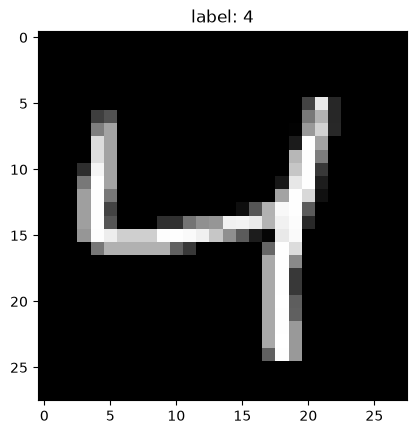

In [18]:
# 컨볼루션
from tensorflow.keras.datasets import mnist  
import matplotlib.pyplot as plt

(x_train, t_train), (x_test, t_test) = mnist.load_data()

plt.imshow(x_train[2], cmap='gray')   
plt.title(f"label: {t_train[2]}")     
plt.show()

In [19]:
# 수평 필터 (가로 경계선 검출)
horizontal_filter = np.array([[ 1.,  1.,  1.],
                              [ 0.,  0.,  0.],
                              [-1., -1., -1.]])  

# 수직 필터 (세로 경계선 검출)
vertical_filter = np.array([[1., 0., -1.],
                            [1., 0., -1.],
                            [1., 0., -1.]])      

In [20]:
test_image = x_train[2]                      # (28, 28), 값 범위 0~255
original_image_size = test_image.shape[0]    # 28
filter_size = horizontal_filter.shape[0]     # 3

# 출력 크기 = (입력 크기 - 필터 크기) / stride + 1  (패딩 없음, stride=1)
output_size = original_image_size - filter_size + 1   # 28 - 3 + 1 = 26

print("original_image_size", original_image_size)   # 28
print("filter_size", filter_size)                   # 3
print("output_size", output_size)                   # 26

original_image_size 28
filter_size 3
output_size 26


In [24]:
filter_size = 3
def get_conv_image(filter):
    filtered_image = np.zeros((output_size, output_size))   # ✅ conv_output_size → output_size
    for i in range(output_size):                            # ✅
        for j in range(output_size):                        # ✅
            indice_image = test_image[i:i + filter_size, j:j + filter_size] * filter
            indice_sum = np.sum(indice_image)

            if indice_sum > 255:
                indice_sum = 255

            filtered_image[i, j] = indice_sum
    return filtered_image

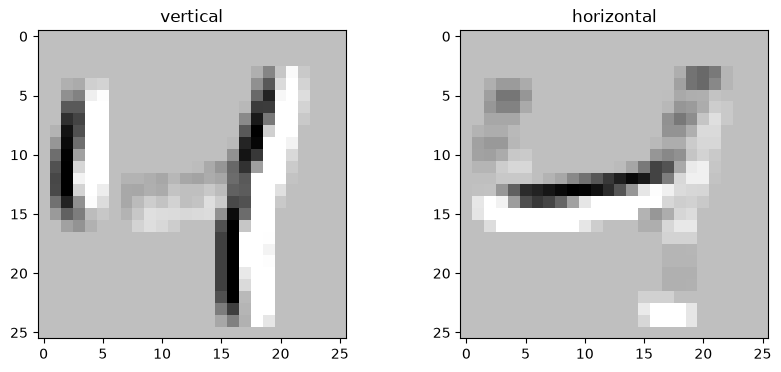

In [27]:
vertical_filtered_image = get_conv_image(vertical_filter)
horizontal_filtered_image = get_conv_image(horizontal_filter)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.title("vertical")
plt.imshow(vertical_filtered_image, cmap="gray")

plt.subplot(1, 2, 2)
plt.title("horizontal")
plt.imshow(horizontal_filtered_image, cmap="gray")

plt.show()

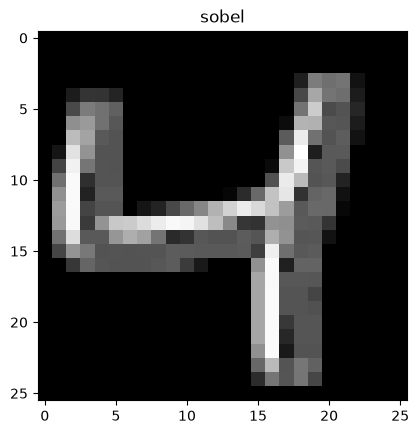

In [28]:
sobel_image = np.sqrt(np.square(horizontal_filtered_image) + np.square(vertical_filtered_image))

plt.title("sobel")
plt.imshow(sobel_image, cmap="gray")
plt.show()

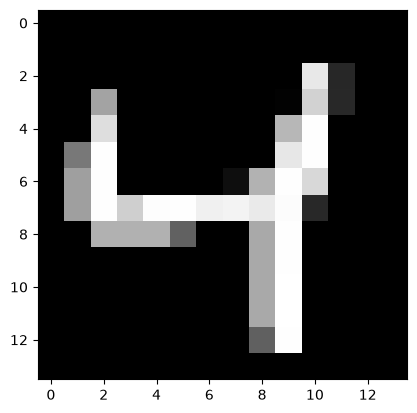

In [30]:
#맥스풀링
import numpy as np
import matplotlib.pyplot as plt

image = x_train[2]
image_x = image.shape[0]
image_y = image.shape[1]

new_image_x = int(image_x/2)
new_image_y = int(image_y/2)

pooled_image = np.zeros((new_image_x, new_image_y))
for x in range(0, image_x, 2):
    for y in range(0, image_y, 2):
        pooled_image[int(x/2), int(y/2)] = np.max(image[x:x+2, y:y+2])

plt.imshow(pooled_image, cmap="gray")
plt.show()

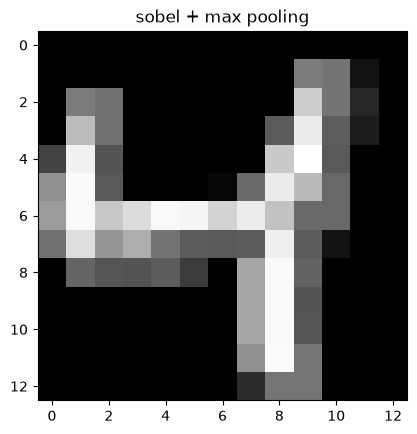

In [35]:
#맥스풀링 (소벨 이미지)
image = sobel_image          # ← 여기만 x_train[2] 에서 sobel_image 로 변경
image_x = image.shape[0]     # 26
image_y = image.shape[1]     # 26

new_image_x = int(image_x/2) # 13
new_image_y = int(image_y/2) # 13

pooled_image = np.zeros((new_image_x, new_image_y))
for x in range(0, image_x, 2):
    for y in range(0, image_y, 2):
        pooled_image[int(x/2), int(y/2)] = np.max(image[x:x+2, y:y+2])

plt.title("sobel + max pooling")
plt.imshow(pooled_image, cmap="gray")
plt.show()

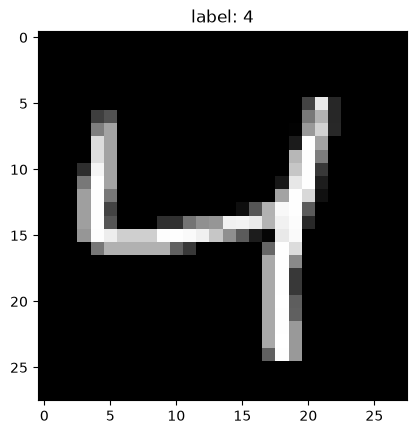

In [36]:
# 컨볼루션
from tensorflow.keras.datasets import mnist  
import matplotlib.pyplot as plt

(x_train, t_train), (x_test, t_test) = mnist.load_data()

plt.imshow(x_train[2], cmap='gray')   
plt.title(f"label: {t_train[2]}")     
plt.show()

In [37]:
x_train.shape,x_test.shape

((60000, 28, 28), (10000, 28, 28))

In [38]:
x_train,x_test=x_train/255.0,x_test/255.0

In [ ]:
import tensorflow as tf

model = tf.keras.models.Sequential([
    tf.keras.layers.Reshape((28, 28, 1), input_shape=(28, 28)),  # (28,28) → (28,28,1) 채널 추가
    tf.keras.layers.Conv2D(16, 3, activation="relu"),            # 3x3 필터 16개
    tf.keras.layers.Flatten(),                                   # 1줄로 펼치기
    tf.keras.layers.Dense(128, activation="relu"),               # 은닉층
    tf.keras.layers.Dense(10, activation="softmax")              # 출력층: 숫자 0~9 (10개)
])



Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 reshape (Reshape)           (None, 28, 28, 1)         0         
                                                                 
 conv2d (Conv2D)             (None, 26, 26, 16)        160       
                                                                 
 flatten (Flatten)           (None, 10816)             0         
                                                                 
 dense_2 (Dense)             (None, 128)               1384576   
                                                                 
 dense_3 (Dense)             (None, 10)                1290      
                                                                 
Total params: 1386026 (5.29 MB)
Trainable params: 1386026 (5.29 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


#### Conv2D(16, 3 or (3,3), padding='valid', input_shape=(28, 28, 1), activation='relu')
- 첫번째 인자 : 컨볼루션 필터의 수
- 두번째 인자 : 컨볼루션 커널의 (행, 열) 크기
- padding : 경계 처리 방법 정의.
    - 'valid' : 유효한 영역만 출력.출력 이미지 사이즈는 입력 사이즈보다 작아진다.
    - 'same' : 출력 이미지 사이즈가 입력 이미지 사이즈와 동일하다.
- input_shape : 샘플 수를 제외한 입력 형태 정의. 모델에서 첫 레이어일 때만 정의한다.
    - (행, 열, 채널 수)로 정의한다. 흑백영상인 경우에는 채널이 1이고, 컬러(RGB)영상인 경우에는 채널을 3으로 설정한다.
- activation : 활성화 함수를 설정한다.
    - 'linear' : 입력뉴런과 가중치로 계산된 결과값이 그대로 출력으로 나온다.default=None
    - 'relu' : rectifier 함수, 은익층에 주로 쓰인다.
    - 'sigmoid' : 시그모이드 함수, 이진 분류 문제에서 출력층에 주로 쓰인다.
    - 'softmax' : 소프트맥스 함수, 다중 클래스 분류 문제에서 출력층에 주로 쓰인다.

In [40]:
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])



In [41]:
model.fit(x_train, t_train, epochs=5)

Epoch 1/5
1875/1875 [==============================] - 10s 5ms/step - loss: 0.1515 - accuracy: 0.9550
Epoch 2/5
1875/1875 [==============================] - 9s 5ms/step - loss: 0.0469 - accuracy: 0.9854
Epoch 3/5
1875/1875 [==============================] - 9s 5ms/step - loss: 0.0240 - accuracy: 0.9919
Epoch 4/5
1875/1875 [==============================] - 9s 5ms/step - loss: 0.0157 - accuracy: 0.9947
Epoch 5/5
1875/1875 [==============================] - 9s 5ms/step - loss: 0.0107 - accuracy: 0.9963


In [43]:
model.evaluate(x_test, t_test, verbose=2)

313/313 - 1s - loss: 0.0616 - accuracy: 0.9828 - 503ms/epoch - 2ms/step


[0.06161731109023094, 0.9828000068664551]

In [ ]:
model.summary()
#컨볼루젼 연산을하면 ,26,26으로 만들어짐 /필터 16개 / 
# 컨볼루젼 연산에서 사용된 파라메터 커널갯수(16)커널사이즈 3x3=9 +1(바이어스) 10

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 reshape (Reshape)           (None, 28, 28, 1)         0         
                                                                 
 conv2d (Conv2D)             (None, 26, 26, 16)        160       
                                                                 
 flatten (Flatten)           (None, 10816)             0         
                                                                 
 dense_2 (Dense)             (None, 128)               1384576   
                                                                 
 dense_3 (Dense)             (None, 10)                1290      
                                                                 
Total params: 1386026 (5.29 MB)
Trainable params: 1386026 (5.29 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [46]:
#functional API사용
#함수를 호출하듯이 사용하는 방식
from tensorflow import keras
from tensorflow.keras import layers

inputs = keras.Input(shape=(28, 28))
x = layers.Reshape((28, 28, 1))(inputs)
x = layers.Conv2D(16, 3, activation="relu")(x)
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dense(10, activation="softmax")(x)
outputs = x

model = keras.Model(inputs, outputs)
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 28, 28)]          0         
                                                                 
 reshape_1 (Reshape)         (None, 28, 28, 1)         0         
                                                                 
 conv2d_1 (Conv2D)           (None, 26, 26, 16)        160       
                                                                 
 flatten_1 (Flatten)         (None, 10816)             0         
                                                                 
 dense_4 (Dense)             (None, 128)               1384576   
                                                                 
 dense_5 (Dense)             (None, 10)                1290      
                                                                 
Total params: 1386026 (5.29 MB)
Trainable params: 1386026 (5.

In [51]:
#풀링사용
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Reshape, Conv2D, MaxPooling2D, Flatten, Dense

model = Sequential()
model.add(Reshape((28, 28, 1), input_shape=(28, 28)))           # (28,28) → (28,28,1)
model.add(Conv2D(16, kernel_size=(3, 3), activation="relu"))    # → (26,26,16)
model.add(MaxPooling2D(pool_size=(2, 2)))                       # → (13,13,16) 풀링
model.add(Flatten())                                            # → 2704
model.add(Dense(128, activation="relu"))
model.add(Dense(10, activation="softmax"))

In [52]:
model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

In [53]:
  # 학습
model.fit(x_train / 255.0, t_train, epochs=5)

Epoch 1/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.7866 - accuracy: 0.7821
Epoch 2/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.3276 - accuracy: 0.9024
Epoch 3/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.2710 - accuracy: 0.9192
Epoch 4/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.2265 - accuracy: 0.9320
Epoch 5/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.1908 - accuracy: 0.9435


In [57]:
loss, acc = model.evaluate(x_test, t_test, verbose=2)
print("테스트 loss :", loss)
print("테스트 accuracy :", acc)

313/313 - 0s - loss: 26.1748 - accuracy: 0.9384 - 334ms/epoch - 1ms/step
테스트 loss : 26.1748046875
테스트 accuracy : 0.9383999705314636


In [59]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Reshape, Conv2D, MaxPooling2D, Flatten, Dense

model = Sequential()
model.add(Reshape((28, 28, 1), input_shape=(28, 28)))           # (28,28) → (28,28,1)
model.add(Conv2D(16, kernel_size=(3, 3), activation="relu"))    # → (26,26,16)
model.add(MaxPooling2D(pool_size=(2, 2)))                       # → (13,13,16)
model.add(Conv2D(32, kernel_size=(3, 3), activation="relu"))    # → (11,11,32)
model.add(MaxPooling2D(pool_size=(2, 2)))                       # → (5,5,32)
model.add(Flatten())                                            # → 800
model.add(Dense(128, activation="relu"))
model.add(Dense(10, activation="softmax"))

model.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 reshape_3 (Reshape)         (None, 28, 28, 1)         0         
                                                                 
 conv2d_3 (Conv2D)           (None, 26, 26, 16)        160       
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 13, 13, 16)        0         
 g2D)                                                            
                                                                 
 conv2d_4 (Conv2D)           (None, 11, 11, 32)        4640      
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 5, 5, 32)          0         
 g2D)                                                            
                                                                 
 flatten_3 (Flatten)         (None, 800)              

In [60]:
#패딩사용
model = Sequential()
model.add(Reshape((28, 28, 1), input_shape=(28, 28)))
model.add(Conv2D(16, kernel_size=(3, 3), padding="same", activation="relu"))  # → (28,28,16)
model.add(MaxPooling2D(pool_size=(2, 2)))                                     # → (14,14,16)
model.add(Conv2D(32, kernel_size=(3, 3), padding="same", activation="relu"))  # → (14,14,32)
model.add(MaxPooling2D(pool_size=(2, 2)))                                     # → (7,7,32)
model.add(Flatten())                                                          # → 1568
model.add(Dense(128, activation="relu"))
model.add(Dense(10, activation="softmax"))

model.summary()

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

model.fit(x_train, t_train, epochs=5)

loss, acc = model.evaluate(x_test, t_test, verbose=2)
print("테스트 loss :", loss)
print("테스트 accuracy :", acc)

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 reshape_4 (Reshape)         (None, 28, 28, 1)         0         
                                                                 
 conv2d_5 (Conv2D)           (None, 28, 28, 16)        160       
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 14, 14, 16)        0         
 g2D)                                                            
                                                                 
 conv2d_6 (Conv2D)           (None, 14, 14, 32)        4640      
                                                                 
 max_pooling2d_4 (MaxPoolin  (None, 7, 7, 32)          0         
 g2D)                                                            
                                                                 
 flatten_4 (Flatten)         (None, 1568)             

In [ ]:
#이미지분류 cifar10

In [63]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import datasets, layers, models

In [69]:
cifar10 = datasets.cifar10
(train_images, train_labels), (test_images, test_labels) = cifar10.load_data()

In [70]:
print("Train samples", train_images.shape, train_labels.shape)
print("Test samples", test_images.shape, test_labels.shape)

Train samples (50000, 32, 32, 3) (50000, 1)
Test samples (10000, 32, 32, 3) (10000, 1)


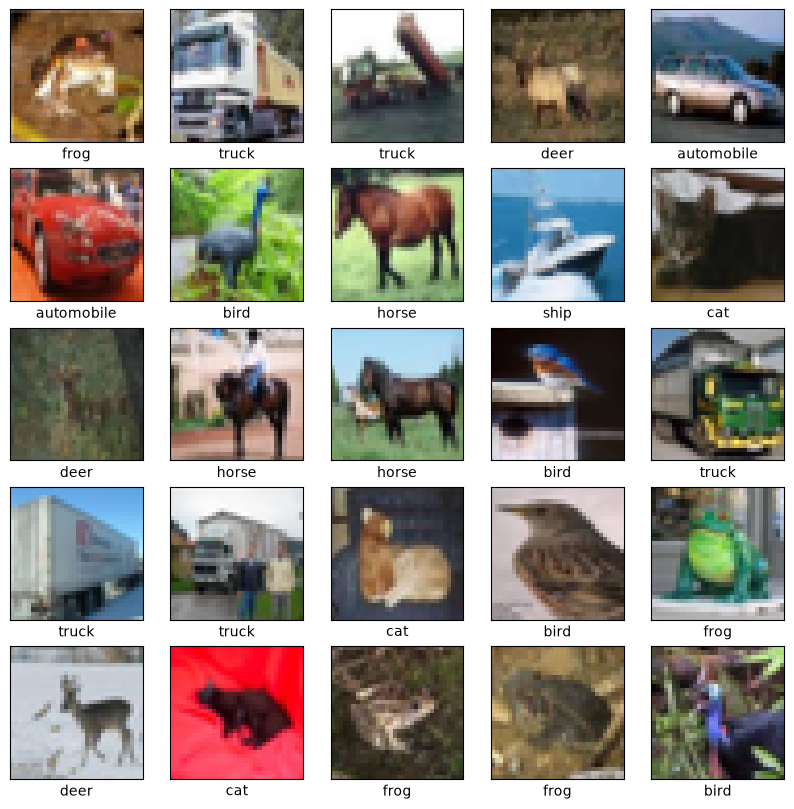

In [71]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)              # 5x5 칸 중 i+1번째 칸
    plt.xticks([])                        # x축 눈금 없애기
    plt.yticks([])                        # y축 눈금 없애기
    plt.grid(False)
    plt.imshow(train_images[i])           # 컬러 이미지라 cmap 필요 없음
    plt.xlabel(class_names[train_labels[i][0]])   # 정답 번호 → 이름
plt.show()

In [73]:
#전처리작업
train_images=train_images/255.0
test_images=test_images/255.0

In [75]:

model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation="relu", input_shape=(32, 32, 3)))  # → (30,30,32)
model.add(layers.MaxPooling2D((2, 2)))                                            # → (15,15,32)
model.add(layers.Conv2D(64, (3, 3), activation="relu"))                           # → (13,13,64)
model.add(layers.MaxPooling2D((2, 2)))                                            # → (6,6,64)
model.add(layers.Conv2D(64, (3, 3), activation="relu"))                           # → (4,4,64)
model.add(layers.Flatten())                                                       # → 1024
model.add(layers.Dense(64, activation="relu"))
model.add(layers.Dense(10, activation="softmax"))                                 # 10개 클래스
model.summary()

Model: "sequential_6"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_10 (Conv2D)          (None, 30, 30, 32)        896       
                                                                 
 max_pooling2d_7 (MaxPoolin  (None, 15, 15, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_11 (Conv2D)          (None, 13, 13, 64)        18496     
                                                                 
 max_pooling2d_8 (MaxPoolin  (None, 6, 6, 64)          0         
 g2D)                                                            
                                                                 
 conv2d_12 (Conv2D)          (None, 4, 4, 64)          36928     
                                                                 
 flatten_6 (Flatten)         (None, 1024)             

In [76]:
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

In [77]:
history = model.fit(train_images, train_labels, epochs=10)


Epoch 1/10
1563/1563 [==============================] - 10s 6ms/step - loss: 1.4955 - accuracy: 0.4588
Epoch 2/10
1563/1563 [==============================] - 9s 6ms/step - loss: 1.1379 - accuracy: 0.5992
Epoch 3/10
1563/1563 [==============================] - 9s 6ms/step - loss: 0.9901 - accuracy: 0.6544
Epoch 4/10
1563/1563 [==============================] - 9s 6ms/step - loss: 0.8953 - accuracy: 0.6860
Epoch 5/10
1563/1563 [==============================] - 9s 6ms/step - loss: 0.8236 - accuracy: 0.7127
Epoch 6/10
1563/1563 [==============================] - 9s 6ms/step - loss: 0.7596 - accuracy: 0.7330
Epoch 7/10
1563/1563 [==============================] - 9s 6ms/step - loss: 0.7045 - accuracy: 0.7535
Epoch 8/10
1563/1563 [==============================] - 9s 6ms/step - loss: 0.6645 - accuracy: 0.7662
Epoch 9/10
1563/1563 [==============================] - 9s 6ms/step - loss: 0.6263 - accuracy: 0.7805
Epoch 10/10
1563/1563 [==============================] - 9s 6ms/step - loss: 0.58

In [78]:
test_loss, test_acc = model.evaluate(test_images, test_labels)
print("Test loss", test_loss)
print("Test accuracy",test_acc)

313/313 [==============================] - 1s 2ms/step - loss: 0.8764 - accuracy: 0.7082
Test loss 0.8763747811317444
Test accuracy 0.7081999778747559
